In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import seaborn as sns


In [56]:
# Dataset Breast Cancer Wisconsin (Diagnostic) desde UCI
df = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data", header=None)

# Nombres reales (según wdbc.names): 10 medidas x 3 bloques (media, error estándar, peor valor)
medidas = ["radius", "texture", "perimeter", "area", "smoothness",
           "compactness", "concavity", "concave points", "symmetry", "fractal dimension"]
columnas = (["ID", "Diagnosis"]
            + [f"mean {m}" for m in medidas]
            + [f"{m} error" for m in medidas]
            + [f"worst {m}" for m in medidas])
df.columns = columnas
print("Primeras filas del dataset original:")
print(df.head())

Primeras filas del dataset original:
         ID Diagnosis  mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  \
0    842302         M        17.99         10.38          122.80     1001.0          0.11840           0.27760   
1    842517         M        20.57         17.77          132.90     1326.0          0.08474           0.07864   
2  84300903         M        19.69         21.25          130.00     1203.0          0.10960           0.15990   
3  84348301         M        11.42         20.38           77.58      386.1          0.14250           0.28390   
4  84358402         M        20.29         14.34          135.10     1297.0          0.10030           0.13280   

   mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  \
0          0.3001              0.14710         0.2419                 0.07871        1.0950         0.9053   
1          0.0869              0.07017         0.1812     

In [57]:
# Revisar datos 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   Diagnosis                569 non-null    str    
 2   mean radius              569 non-null    float64
 3   mean texture             569 non-null    float64
 4   mean perimeter           569 non-null    float64
 5   mean area                569 non-null    float64
 6   mean smoothness          569 non-null    float64
 7   mean compactness         569 non-null    float64
 8   mean concavity           569 non-null    float64
 9   mean concave points      569 non-null    float64
 10  mean symmetry            569 non-null    float64
 11  mean fractal dimension   569 non-null    float64
 12  radius error             569 non-null    float64
 13  texture error            569 non-null    float64
 14  perimeter error          569 non-null

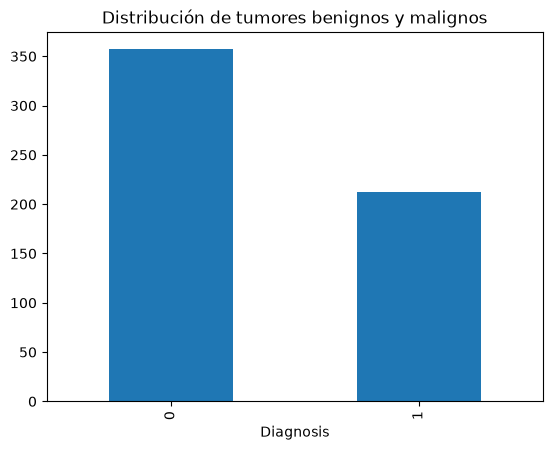

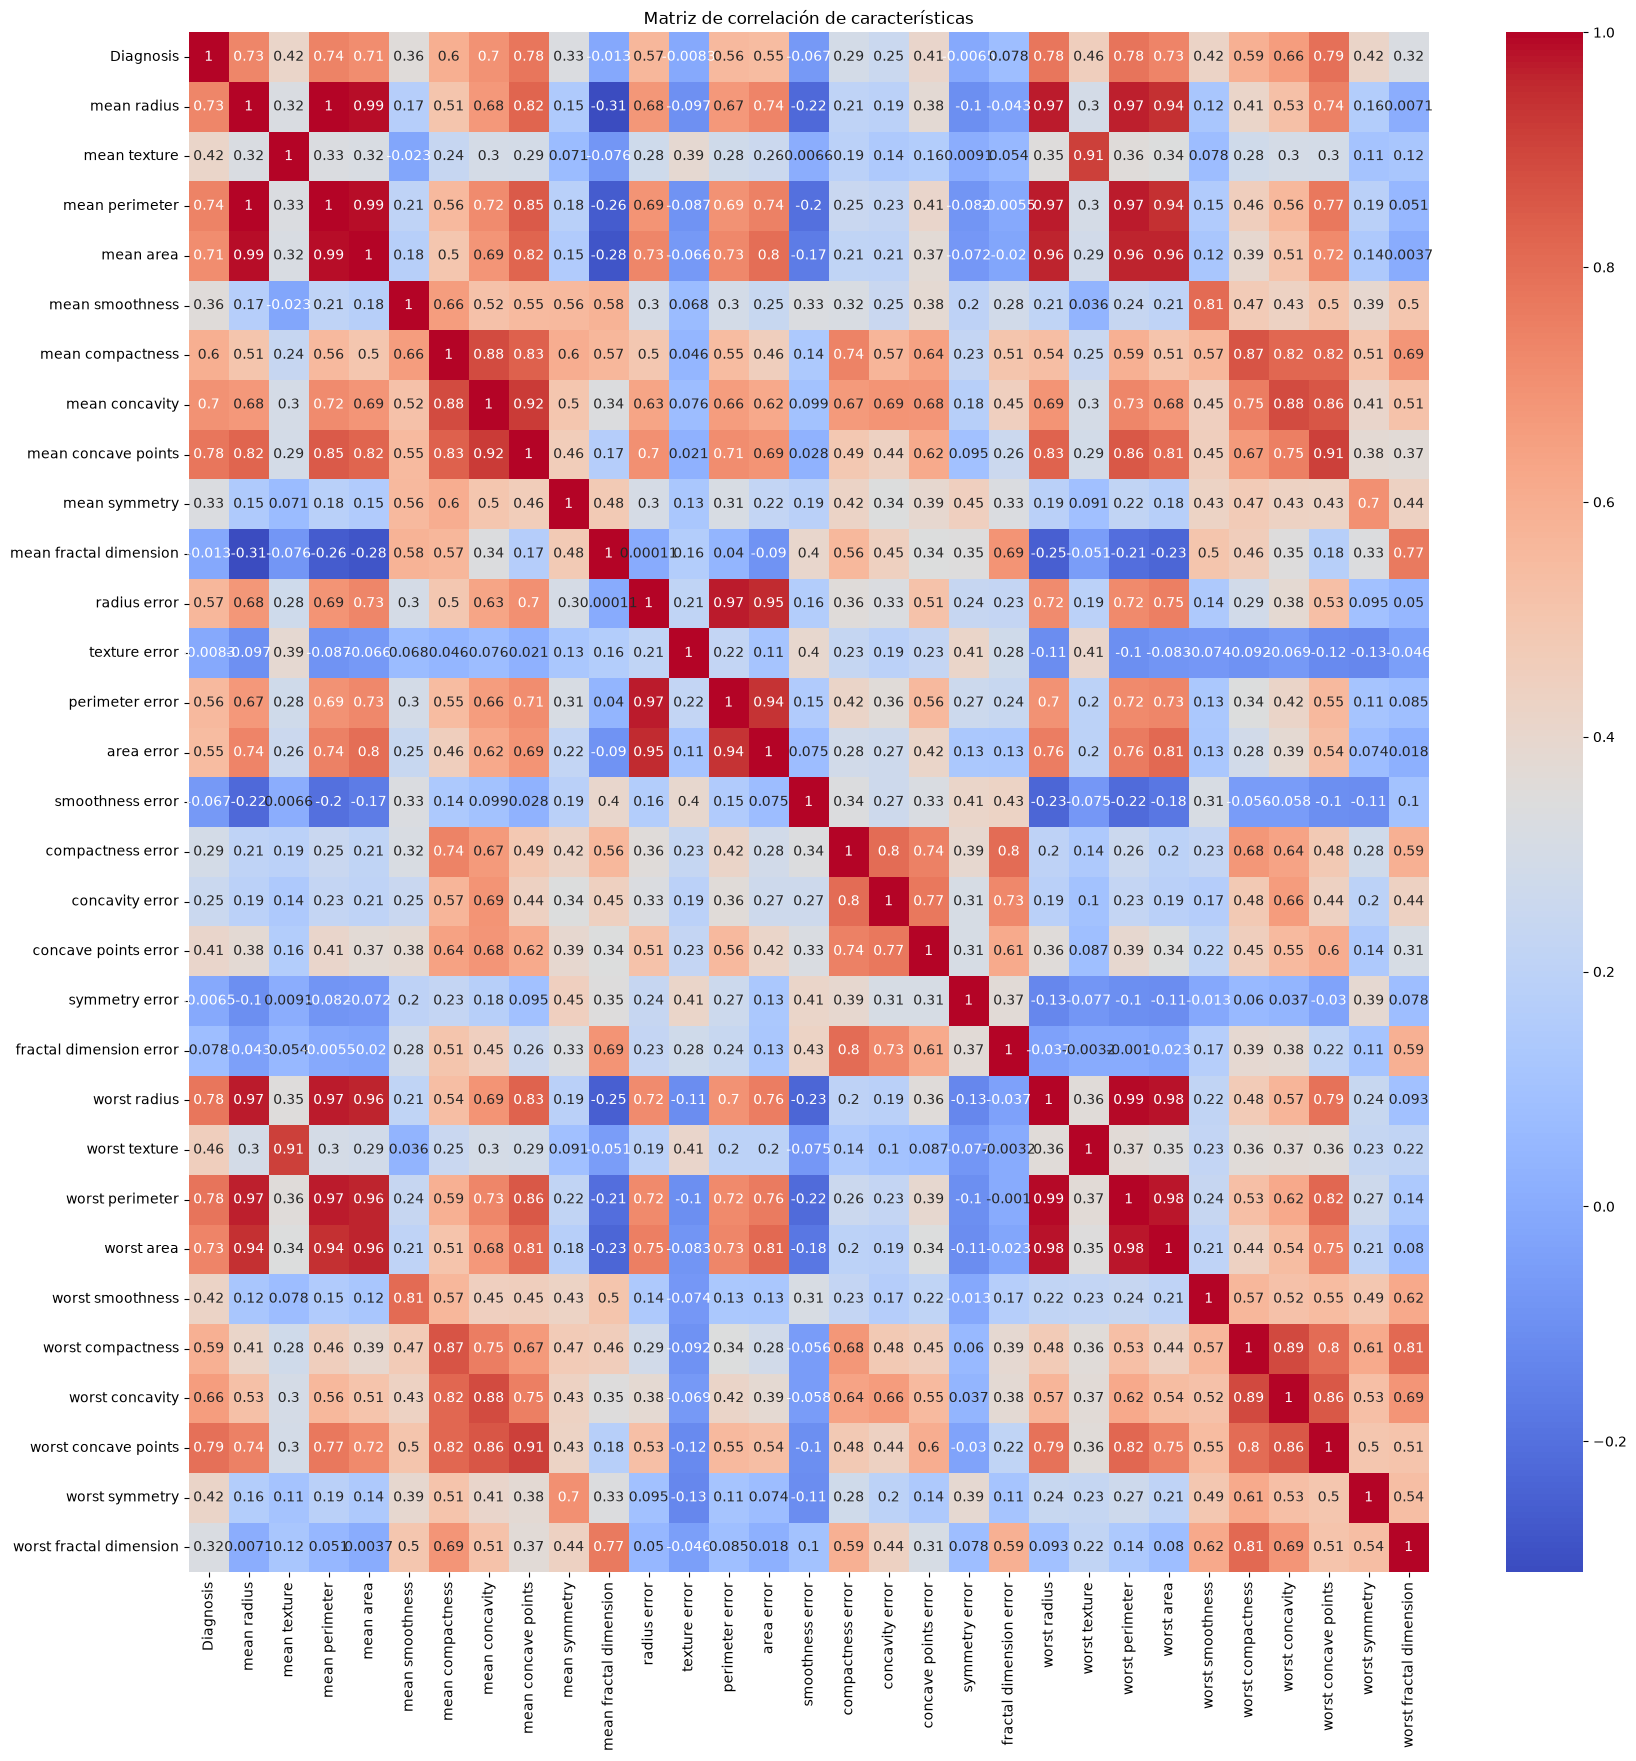

In [58]:
# Revisar estadistica de pearson
#importar sns

#Tratamiento de categoricos
df["Diagnosis"] = df["Diagnosis"].map({"M": 1, "B": 0})
df["Diagnosis"].value_counts()
df["Diagnosis"].value_counts().plot(kind="bar", title="Distribución de tumores benignos y malignos")
plt.show()
df.drop(columns=["ID"]).corr()
#en manera de heatmap

plt.figure(figsize=(20, 20))
sns.heatmap(df.drop(columns=["ID"]).corr(), annot=True, cmap="coolwarm")
plt.title("Matriz de correlación de características")
plt.show()

## 2. Análisis Exploratorio y Visualización

- **Instrucción con Pandas:** Utiliza los métodos correspondientes del DataFrame para obtener un resumen estadístico completo (conteo, media, desviación estándar, mínimos, cuartiles y máximos) de las principales variables de forma, así como para revisar los tipos de datos y detectar la presencia de valores nulos o anomalías estructurales.
- **Instrucción con Matplotlib:** Genera un diagrama de dispersión (*scatter plot*) que relacione la media del radio de los núcleos (`mean radius`) en el eje X con la media de la textura (`mean texture`) en el eje Y. Asegúrate de diferenciar visualmente mediante colores y leyendas a los tumores benignos de los malignos, incorporando etiquetas claras en los ejes, título y cuadrícula.

In [59]:
# Resumen estadístico completo
df.describe()

,ID,Diagnosis,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,...,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,0.372583,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,...,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,0.483918,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,...,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,0.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,...,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,0.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,...,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,0.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,...,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,1.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,...,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,1.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,...,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


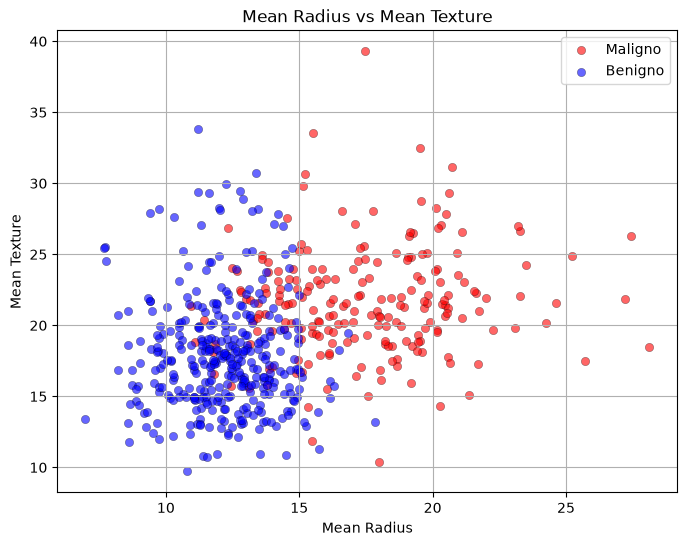

In [60]:
# Diagrama de dispersión: rojo = Maligno (1), azul = Benigno (0)
# (Diagnosis ya es numérico: se mapeó M->1, B->0 en la celda de correlación)
plt.figure(figsize=(8, 6))
for valor, color, etiqueta in [(1, "red", "Maligno"), (0, "blue", "Benigno")]:
    sub = df[df["Diagnosis"] == valor]
    plt.scatter(sub["mean radius"], sub["mean texture"], c=color, label=etiqueta, alpha=0.6, edgecolors="k", linewidths=0.3)
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Mean Radius vs Mean Texture")
plt.legend()
plt.grid(True)
plt.show()

## 3. Limpieza y Preprocesamiento de Datos

- **Detección y Manejo de Nulos:** Revisa si existen valores faltantes o celdas vacías en el DataFrame. Utiliza Pandas para verificar celdas con espacios vacíos o códigos especiales de valores nulos (`NaN`) y decide la estrategia de limpieza adecuada (imputación con mediana o eliminación si el porcentaje es mínimo).
- **Tratamiento de valores atípicos (Outliers):** Emplea funciones de NumPy (como percentiles) para calcular el Rango Intercuartílico (IQR) en una de las variables clave del tamaño del tumor (por ejemplo, `mean area`). Establece los límites inferior y superior basados en 1.5 veces el IQR, y filtra el DataFrame para conservar únicamente las muestras que se encuentren dentro de este rango razonable.

In [61]:
# Detección de nulos, celdas vacías y códigos especiales
print("Nulos por columna (NaN):", df.isna().sum().sum())
especiales = df.isin(["", " ", "?", "NA", "N/A", "null"]).sum().sum()
print("Celdas vacías / códigos especiales:", especiales)
# Resultado: 0 nulos -> no hace falta imputar ni eliminar filas


Nulos por columna (NaN): 0
Celdas vacías / códigos especiales: 0


In [62]:
# Outliers con IQR sobre "mean area" (variable clave del tamaño del tumor)
q1, q3 = np.percentile(df["mean area"], [25, 75])
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
print(f"Q1={q1:.2f}  Q3={q3:.2f}  IQR={iqr:.2f}")
print(f"Límites: [{limite_inf:.2f}, {limite_sup:.2f}]")

df_clean = df[(df["mean area"] >= limite_inf) & (df["mean area"] <= limite_sup)].copy()
print(f"Filas antes: {len(df)} | después: {len(df_clean)} | eliminadas: {len(df) - len(df_clean)}")

Q1=420.30  Q3=782.70  IQR=362.40
Límites: [-123.30, 1326.30]
Filas antes: 569 | después: 544 | eliminadas: 25


## 4. Entrenamiento y Evaluación del Árbol de Decisión

- **Preparación de los datos:** Separa el DataFrame limpio en dos componentes: la matriz de características independientes (`X`, excluyendo la columna de ID y la etiqueta de diagnóstico) y el vector de etiquetas objetivo (`y`, convirtiendo los valores categóricos 'M' y 'B' a valores numéricos binarios, por ejemplo, 1 para Maligno y 0 para Benigno).
- **Partición del conjunto:** Divide los datos en conjuntos de entrenamiento y prueba utilizando la función de Scikit-Learn, asignando un 25% de los datos para la prueba y fijando una semilla de aleatoriedad (`random_state=42`) para garantizar la reproducibilidad.
- **Modelado y Métricas:** Inicializa un clasificador de árbol de decisión con Scikit-Learn (`DecisionTreeClassifier`), entrénalo con el conjunto de entrenamiento y genera predicciones sobre el conjunto de prueba. Evalúa el desempeño del modelo calculando la exactitud (*Accuracy*) e imprimiendo el reporte de clasificación detallado (`classification_report`).
- **Visualización de la Estructura:** Utiliza la función de ploteo de árboles de decisión de Scikit-Learn (`plot_tree`) en combinación con Matplotlib para graficar la estructura jerárquica del modelo entrenado, limitando la profundidad si es necesario para una mejor legibilidad, y especificando los nombres de las características y clases correspondientes.

In [63]:
#Quitar la columna de IDs y la columna de diagnóstico
X = df_clean.drop(['ID', 'Diagnosis'], axis=1) #se saca diagnosis porque si no se hace un data leakage
y = df_clean['Diagnosis'] #Nuestra etiqueta objetivo (1 = Maligno, 0 = Benigno; ya mapeada arriba)

# Dividir los datos en conjuntos de entrenamiento y prueba (25% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Entrenar el modelo de árbol de decisión
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# Predicciones y métricas
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"]))

Accuracy: 0.9117647058823529
              precision    recall  f1-score   support

     Benigno       0.91      0.94      0.93        79
     Maligno       0.91      0.88      0.89        57

    accuracy                           0.91       136
   macro avg       0.91      0.91      0.91       136
weighted avg       0.91      0.91      0.91       136



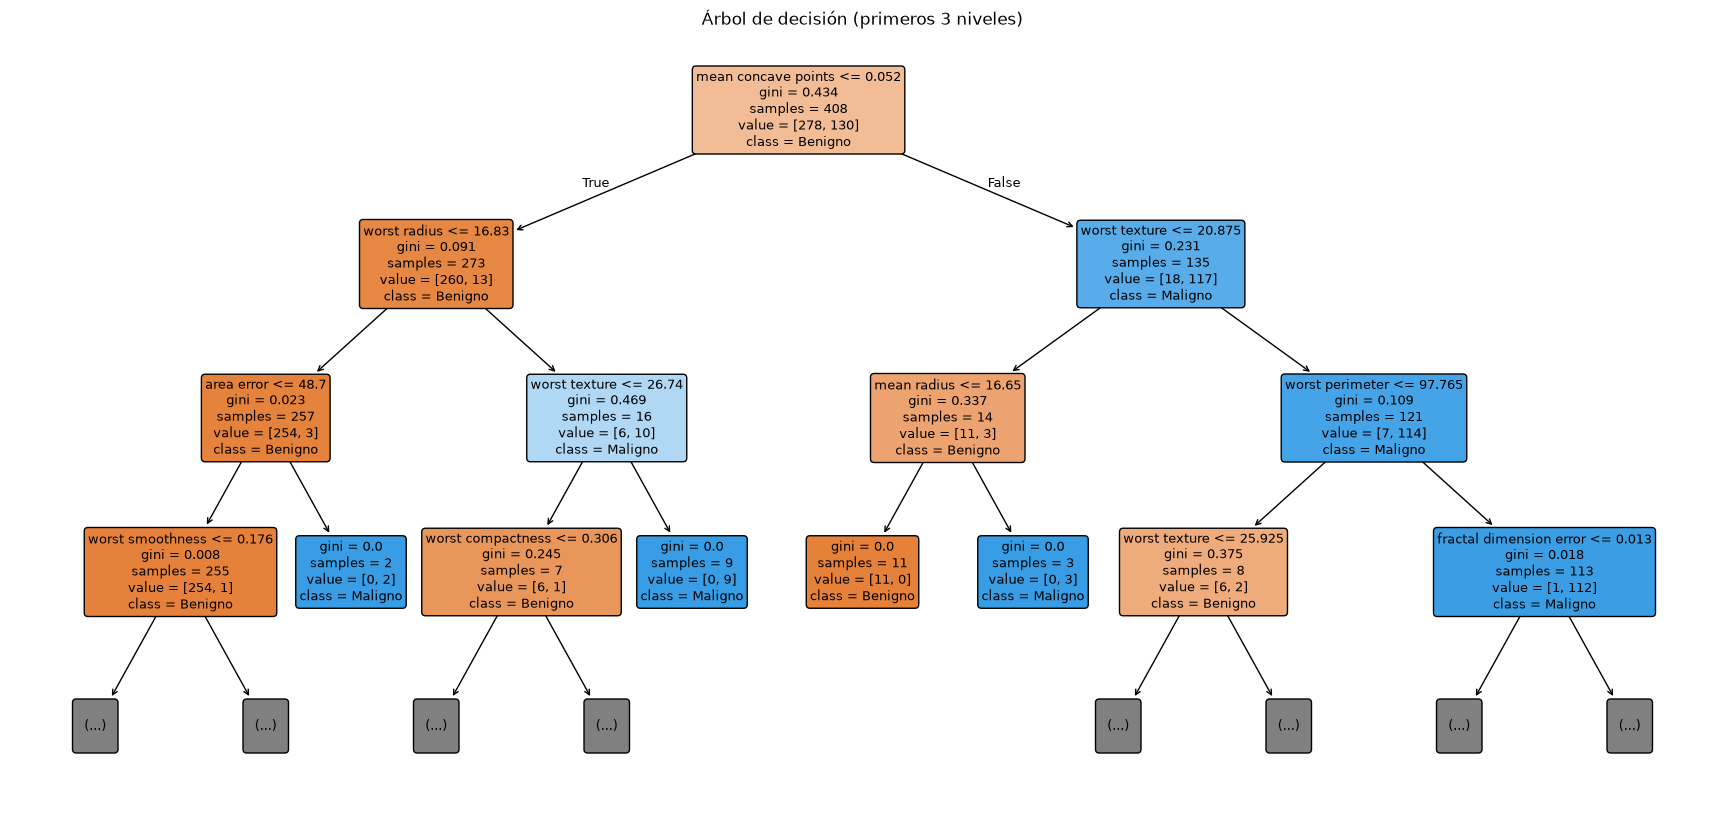

In [64]:
# Estructura del árbol (profundidad limitada para legibilidad)
plt.figure(figsize=(22, 10))
plot_tree(clf, max_depth=3, feature_names=X.columns, class_names=["Benigno", "Maligno"],
          filled=True, rounded=True, fontsize=9)
plt.title("Árbol de decisión (primeros 3 niveles)")
plt.show()

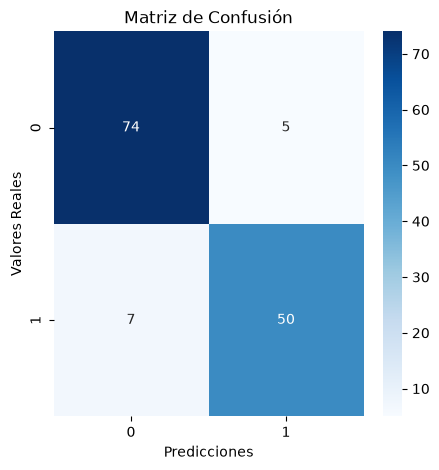

In [66]:
#importar confusion matrix de sklearn
from sklearn.metrics import confusion_matrix
#Mostrar la matriz de confusion
cm = confusion_matrix(y_test, y_pred)
#con figuras
fig, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
plt.title("Matriz de Confusión")
plt.xlabel("Predicciones")
plt.ylabel("Valores Reales")
plt.show()